# 06 – PhoBERT

Mục tiêu: fine-tune PhoBERT (`vinai/phobert-base`) trên cùng split và cùng metric với baseline ML và BiLSTM, rồi so sánh với SVM (Macro-F1 test = 0,7399) và BiLSTM (0,7637 ± 0,0068).

Quy tắc xuyên suốt :
- Dùng cột **`text_seg`** (đã tách từ VnCoreNLP), không dùng `text_clean`.
- Chọn epoch và chọn cấu hình chỉ dựa trên **dev**.
- Tập **test chấm một lần**.
- Thứ tự lớp cố định: negative, neutral, positive.
- Trọng số lớp trong loss tính từ train, cùng công thức với BiLSTM.

## 1. Cài đặt, nạp dữ liệu

Mount Drive, cài `transformers`, nạp `data_clean.csv`, cố định seed. Hàm `set_seed` sẽ được gọi lại ở mỗi lần huấn luyện để các seed khác nhau cho kết quả khác nhau nhưng chạy lại cùng seed thì ra cùng kết quả.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q transformers

import os, time, random
import numpy as np
import pandas as pd
import torch
import transformers

PROJECT     = '/content/drive/MyDrive/project1_vsfc'
DATA_DIR    = f'{PROJECT}/data'
RESULTS_DIR = f'{PROJECT}/results'

SEED   = 42
LABELS = ['negative', 'neutral', 'positive']

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)
# --- Nạp dữ liệu ---
df = pd.read_csv(f'{DATA_DIR}/data_clean.csv', encoding='utf-8-sig', keep_default_na=False)
print('\nKích thước:', df.shape)
print('Các cột:', df.columns.tolist())

# --- Tách 3 tập ---
tr = df[df['split'] == 'train'].reset_index(drop=True)
dv = df[df['split'] == 'dev'].reset_index(drop=True)
te = df[df['split'] == 'test'].reset_index(drop=True)
y_tr, y_dv, y_te = tr['sentiment'].values, dv['sentiment'].values, te['sentiment'].values

cnt = pd.crosstab(df['split'], df['sentiment_name'])[LABELS].loc[['train', 'dev', 'test']]
print('\nSố câu theo lớp:')
print(cnt)

Mounted at /content/drive

Kích thước: (16175, 6)
Các cột: ['split', 'text_raw', 'text_clean', 'text_seg', 'sentiment', 'sentiment_name']

Số câu theo lớp:
sentiment_name  negative  neutral  positive
split                                      
train               5325      458      5643
dev                  705       73       805
test                1409      167      1590


## 2. Hàm đánh giá

Chép từ notebook 05 để số liệu của PhoBERT so sánh trực tiếp được với SVM và BiLSTM:

- `evaluate`: Macro-F1 (metric chính), Accuracy, Precision / Recall / F1 từng lớp.
- `show_report`: báo cáo chi tiết từng lớp.
- `plot_cm`: ma trận nhầm lẫn (số câu và % theo hàng), thứ tự lớp cố định.

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

LABEL_IDS = [0, 1, 2]          # tương ứng LABELS = negative, neutral, positive

def evaluate(y_true, y_pred, name='', split=''):
    """Trả về dict: Macro-F1 (chính), Accuracy, P/R/F1 từng lớp."""
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABEL_IDS, zero_division=0)
    row = {'model': name, 'split': split,
           'macro_f1': f1_score(y_true, y_pred, average='macro', labels=LABEL_IDS, zero_division=0),
           'accuracy': accuracy_score(y_true, y_pred)}
    for i, lab in enumerate(LABELS):
        row[f'P_{lab}'], row[f'R_{lab}'], row[f'F1_{lab}'] = p[i], r[i], f[i]
    return row

def show_report(y_true, y_pred):
    print(classification_report(y_true, y_pred, labels=LABEL_IDS,
                                target_names=LABELS, digits=4, zero_division=0))

def plot_cm(y_true, y_pred, title='', path=None):
    """Ma trận nhầm lẫn: số câu và % theo hàng (hàng = nhãn thật)."""
    cm = confusion_matrix(y_true, y_pred, labels=LABEL_IDS)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([[f'{cm[i, j]}\n({cm_pct[i, j]:.1f}%)' for j in range(3)] for i in range(3)])
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False,
                xticklabels=LABELS, yticklabels=LABELS)
    plt.xlabel('Dự đoán'); plt.ylabel('Nhãn thật'); plt.title(title)
    if path:
        plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()

## 3. Tokenizer PhoBERT và kiểm tra mã hóa

Nạp tokenizer `vinai/phobert-base`, kiểm tra đầu vào có đúng định dạng PhoBERT, rồi mã hóa **toàn bộ** train / dev / test **một lần** (không mã hóa lại trong từng batch cho đỡ chậm).

- `MAX_LEN = 128`.

In [3]:
from transformers import AutoTokenizer

MAX_LEN = 128
tokenizer = AutoTokenizer.from_pretrained('vinai/phobert-base')
assert (tokenizer.cls_token_id, tokenizer.pad_token_id,
        tokenizer.sep_token_id, tokenizer.unk_token_id) == (0, 1, 2, 3)

def encode(texts):
    return tokenizer(texts, truncation=True, max_length=MAX_LEN)['input_ids']

ids_tr = encode(tr['text_seg'].tolist())
ids_dv = encode(dv['text_seg'].tolist())
ids_te = encode(te['text_seg'].tolist())

assert (len(ids_tr), len(ids_dv), len(ids_te)) == (len(tr), len(dv), len(te))
all_ids = ids_tr + ids_dv + ids_te
assert max(len(x) for x in all_ids) <= MAX_LEN
assert all(x[0] == 0 and x[-1] == 2 for x in all_ids), 'Có câu mất <s> hoặc </s> sau khi cắt'

for name, ids in [('train', ids_tr), ('dev', ids_dv), ('test', ids_te)]:
    l = np.array([len(x) for x in ids])
    print(f'{name:5s}: {len(ids):5d} câu | dài nhất {l.max():3d} | số câu bị cắt {int((l == MAX_LEN).sum())}')

config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

train: 11426 câu | dài nhất 128 | số câu bị cắt 1
dev  :  1583 câu | dài nhất 128 | số câu bị cắt 1
test :  3166 câu | dài nhất  84 | số câu bị cắt 0


## 4. Dataset, DataLoader, trọng số lớp

- `Dataset` trả về `(input_ids, nhãn)` từ danh sách đã mã hóa ở ô 3.
- `collate` đệm **động**: mỗi batch chỉ đệm đến độ dài câu dài nhất trong batch đó, `<pad>` = 1, và tạo `attention_mask`.
- `make_loader` dùng `torch.Generator` cố định seed khi xáo trộn, để cùng seed thì thứ tự batch giống nhau, khác seed thì khác nhau.
- `CLASS_W = n / (3 × số câu của lớp)`, **tính từ train**, cùng công thức với BiLSTM (kỳ vọng ≈ 0,7152 / 8,3159 / 0,6749).
- Ở ô này chỉ tạo loader cho **train** và **dev**. Loader cho test để dành đến ô 8, đúng nguyên tắc "test chấm một lần".

In [4]:
from torch.utils.data import Dataset, DataLoader

BATCH      = 32     # batch khi huấn luyện
EVAL_BATCH = 64     # batch khi dự đoán (không cần lưu gradient nên lớn hơn được)
PAD_ID     = tokenizer.pad_token_id   # = 1

class SentDS(Dataset):
    def __init__(self, ids, y):
        assert len(ids) == len(y)
        self.ids, self.y = ids, y
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        return self.ids[i], int(self.y[i])

def collate(batch):
    """Đệm động theo câu dài nhất trong batch, tạo attention_mask."""
    max_len = max(len(x) for x, _ in batch)
    input_ids = torch.full((len(batch), max_len), PAD_ID, dtype=torch.long)
    attn_mask = torch.zeros((len(batch), max_len), dtype=torch.long)
    for i, (x, _) in enumerate(batch):
        input_ids[i, :len(x)] = torch.tensor(x, dtype=torch.long)
        attn_mask[i, :len(x)] = 1
    labels = torch.tensor([y for _, y in batch], dtype=torch.long)
    return input_ids, attn_mask, labels

def make_loader(ids, y, shuffle=False, seed=None):
    g = None
    if shuffle:
        g = torch.Generator()
        g.manual_seed(seed)
    return DataLoader(SentDS(ids, y),
                      batch_size=BATCH if shuffle else EVAL_BATCH,
                      shuffle=shuffle, generator=g, collate_fn=collate)

# --- Trọng số lớp, tính từ train ---
counts  = np.bincount(y_tr, minlength=3)
CLASS_W = torch.tensor(len(y_tr) / (3 * counts), dtype=torch.float)
print('Số câu train theo lớp :', counts.tolist())
print('CLASS_W               :', [round(w, 4) for w in CLASS_W.tolist()])
assert counts.tolist() == [5325, 458, 5643]
assert np.allclose(CLASS_W.numpy(), [0.7152, 8.3159, 0.6749], atol=1e-3)
assert abs((CLASS_W.numpy() * counts).sum() - len(y_tr)) < 1e-3   # mỗi lớp đóng góp n/3

# --- Loader train và dev (test để dành cho ô 8) ---
train_loader = make_loader(ids_tr, y_tr, shuffle=True, seed=42)
dev_loader   = make_loader(ids_dv, y_dv, shuffle=False)
print(f'\nSố batch mỗi epoch: train = {len(train_loader)} | dev = {len(dev_loader)}')

# --- Kiểm tra một batch ---
input_ids, attn_mask, labels = next(iter(train_loader))
print('\ninput_ids :', tuple(input_ids.shape), input_ids.dtype)
print('attn_mask :', tuple(attn_mask.shape), attn_mask.dtype)
print('labels    :', tuple(labels.shape), labels.dtype, '| số câu theo lớp trong batch:',
      torch.bincount(labels, minlength=3).tolist())
assert input_ids.shape == attn_mask.shape and input_ids.shape[0] == BATCH
assert ((input_ids != PAD_ID).long() == attn_mask).all(), 'attention_mask không khớp vị trí đệm'
assert set(labels.tolist()) <= {0, 1, 2}

n_real = int(attn_mask[0].sum())
print('\nCâu đầu batch (token thật rồi đến phần đệm):')
print(' ', tokenizer.convert_ids_to_tokens(input_ids[0][:n_real + 3].tolist()))

# --- Kiểm tra seed: cùng seed thì giống nhau, khác seed thì khác nhau ---
first_labels = lambda s: next(iter(make_loader(ids_tr, y_tr, shuffle=True, seed=s)))[2].tolist()
print('\nCùng seed (42 và 42) cho batch đầu giống nhau :', first_labels(42) == first_labels(42))
print('Khác seed (42 và 43) cho batch đầu khác nhau  :', first_labels(42) != first_labels(43))

Số câu train theo lớp : [5325, 458, 5643]
CLASS_W               : [0.7152, 8.3159, 0.6749]

Số batch mỗi epoch: train = 358 | dev = 25

input_ids : (32, 38) torch.int64
attn_mask : (32, 38) torch.int64
labels    : (32,) torch.int64 | số câu theo lớp trong batch: [18, 1, 13]

Câu đầu batch (token thật rồi đến phần đệm):
  ['<s>', 'môn_học', 'chưa', 'thực_tiễn', ',', 'chưa', 'thu_hút', 'sinh_viên', '.', '</s>', '<pad>', '<pad>', '<pad>']

Cùng seed (42 và 42) cho batch đầu giống nhau : True
Khác seed (42 và 43) cho batch đầu khác nhau  : True


## 5. Mô hình và hàm huấn luyện

Mô hình: `AutoModelForSequenceClassification` từ `vinai/phobert-base`, thêm đầu phân loại 3 lớp (khởi tạo ngẫu nhiên theo seed).

**Cấu hình cố định (chốt trước khi chạy, không chỉnh sau khi xem test):**

| Tham số | Giá trị | Ghi chú |
|---|---|---|
| `MAX_LEN` / `BATCH` | 128 / 32 | Đệm động theo batch |
| `LR` | 2e-5 | Giá trị phổ biến khi fine-tune BERT |
| `WEIGHT_DECAY` | 0,01 | Không áp dụng cho bias và LayerNorm |
| Warmup | 10% số bước, sau đó giảm tuyến tính về 0 | |
| `MAX_EPOCHS` / `PATIENCE` | 5 / 2 | Dừng sớm theo Macro-F1 trên **dev** |
| Gradient clip | 1,0 | Giống BiLSTM |
| Loss | `CrossEntropyLoss(weight=CLASS_W)` | Tính từ logits, vì loss mặc định của mô hình không có trọng số lớp |
| Độ chính xác | fp16 (autocast) | Chạy nhanh hơn trên GPU T4 |

Hàm `train_model(seed)`:
- Chọn epoch tốt nhất theo Macro-F1 dev và **lưu `state_dict` ra đĩa cục bộ** (`/content/ckpt`), không giữ nhiều mô hình trong RAM.
- **Không dùng tập test** trong hàm này. Test chỉ được chấm ở ô 8 bằng các checkpoint đã lưu.


In [5]:
import gc, shutil
import torch.nn as nn
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert device.type == 'cuda', 'Chưa bật GPU: Runtime -> Change runtime type -> T4 GPU'

# --- Cấu hình cố định ---
LR, WEIGHT_DECAY, WARMUP_RATIO = 2e-5, 0.01, 0.1
MAX_EPOCHS, PATIENCE, GRAD_CLIP = 5, 2, 1.0
USE_AMP  = True
CKPT_DIR = '/content/ckpt'
os.makedirs(CKPT_DIR, exist_ok=True)

free_gb = shutil.disk_usage('/content').free / 1e9
print(f'Ổ đĩa còn trống: {free_gb:.1f} GB (cần khoảng 3 GB cho 5 checkpoint)')
assert free_gb > 5, 'Ổ đĩa không đủ chỗ lưu checkpoint'

def new_model():
    return AutoModelForSequenceClassification.from_pretrained('vinai/phobert-base', num_labels=3).to(device)

def load_best(ckpt_path):
    model = new_model()
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    return model.eval()

def make_optimizer(model):
    no_decay = ('bias', 'LayerNorm.weight')
    groups = [
        {'params': [p for n, p in model.named_parameters() if not any(k in n for k in no_decay)],
         'weight_decay': WEIGHT_DECAY},
        {'params': [p for n, p in model.named_parameters() if any(k in n for k in no_decay)],
         'weight_decay': 0.0},
    ]
    assert len(groups[0]['params']) > 0 and len(groups[1]['params']) > 0
    return torch.optim.AdamW(groups, lr=LR)

@torch.no_grad()
def predict(model, loader):
    """Trả về mảng nhãn dự đoán, đúng thứ tự câu trong loader (loader không xáo trộn)."""
    model.eval()
    preds = []
    for input_ids, attn_mask, _ in loader:
        with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
            logits = model(input_ids=input_ids.to(device), attention_mask=attn_mask.to(device)).logits
        preds.append(logits.argmax(-1).cpu())
    return torch.cat(preds).numpy()

def train_model(seed, verbose=True):
    """Huấn luyện 1 seed, chọn epoch theo Macro-F1 dev, lưu checkpoint tốt nhất. KHÔNG dùng test."""
    set_seed(seed)
    loader    = make_loader(ids_tr, y_tr, shuffle=True, seed=seed)
    model     = new_model()
    criterion = nn.CrossEntropyLoss(weight=CLASS_W.to(device))
    optimizer = make_optimizer(model)
    total     = len(loader) * MAX_EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total), total)
    scaler    = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    ckpt      = f'{CKPT_DIR}/phobert_s{seed}.pt'

    best_f1, best_epoch, bad, hist = -1.0, 0, 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        t0 = time.time()
        model.train()
        tot_loss = 0.0
        for input_ids, attn_mask, labels in loader:
            input_ids, attn_mask, labels = input_ids.to(device), attn_mask.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
                logits = model(input_ids=input_ids, attention_mask=attn_mask).logits
            loss = criterion(logits.float(), labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            tot_loss += loss.item()

        res = evaluate(y_dv, predict(model, dev_loader), name=f'phobert_s{seed}', split='dev')
        improved = res['macro_f1'] > best_f1
        hist.append({'epoch': epoch, 'loss': tot_loss / len(loader),
                     'dev_macro_f1': res['macro_f1'], 'dev_f1_neutral': res['F1_neutral'],
                     'sec': time.time() - t0})
        if improved:
            best_f1, best_epoch, bad = res['macro_f1'], epoch, 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
        if verbose:
            print(f'seed {seed} | epoch {epoch} | loss {hist[-1]["loss"]:.4f} | '
                  f'dev Macro-F1 {res["macro_f1"]:.4f} | dev F1 neutral {res["F1_neutral"]:.4f} | '
                  f'{hist[-1]["sec"]:.0f}s' + ('  <- tốt nhất' if improved else ''))
        if bad >= PATIENCE:
            if verbose:
                print(f'Dừng sớm: {PATIENCE} epoch liền không cải thiện.')
            break

    del model, optimizer, scheduler, scaler
    gc.collect(); torch.cuda.empty_cache()
    return {'seed': seed, 'best_epoch': best_epoch, 'best_dev_f1': best_f1, 'hist': hist, 'ckpt': ckpt}

Ổ đĩa còn trống: 120.8 GB (cần khoảng 3 GB cho 5 checkpoint)


## 6. Chạy thử một lần (seed 42)

Huấn luyện PhoBERT với seed 42, in loss và Macro-F1 trên **dev** sau mỗi epoch, vẽ learning curve, rồi nạp lại checkpoint tốt nhất để xem báo cáo từng lớp trên dev.

- Chỉ dùng **dev**. Tập test vẫn chưa được đụng đến.
- Kết quả được lưu vào `RUNS[42]` và sẽ **dùng lại ở ô 7**, nên seed 42 không phải huấn luyện lần nữa.
- Mốc tham chiếu trên dev: SVM đạt Macro-F1 0,7604; BiLSTM trung bình 0,8069.
- Dấu hiệu bất thường cần dừng lại kiểm tra: loss không giảm, F1 neutral gần 0, hoặc Macro-F1 dev dưới 0,70.

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  543MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  543MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


seed 42 | epoch 1 | loss 0.6656 | dev Macro-F1 0.8419 | dev F1 neutral 0.6098 | 49s  <- tốt nhất
seed 42 | epoch 2 | loss 0.3563 | dev Macro-F1 0.8562 | dev F1 neutral 0.6434 | 46s  <- tốt nhất
seed 42 | epoch 3 | loss 0.2640 | dev Macro-F1 0.8608 | dev F1 neutral 0.6562 | 43s  <- tốt nhất
seed 42 | epoch 4 | loss 0.1928 | dev Macro-F1 0.8765 | dev F1 neutral 0.6970 | 43s  <- tốt nhất
seed 42 | epoch 5 | loss 0.1508 | dev Macro-F1 0.8701 | dev F1 neutral 0.6818 | 43s

Tổng thời gian seed 42: 4.3 phút
Epoch tốt nhất: 4 | Macro-F1 dev tốt nhất: 0.8765
Ước tính 5 seed: khoảng 22 phút (nếu các seed dừng sớm tương tự)

  epoch   loss  dev_macro_f1  dev_f1_neutral     sec
     1 0.6656        0.8419          0.6098 49.2434
     2 0.3563        0.8562          0.6434 46.0648
     3 0.2640        0.8608          0.6562 42.8206
     4 0.1928        0.8765          0.6970 42.7992
     5 0.1508        0.8701          0.6818 42.9277


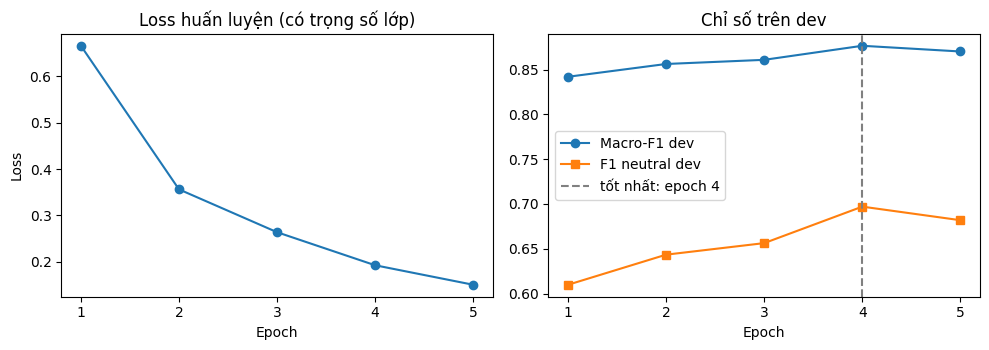


Checkpoint: /content/ckpt/phobert_s42.pt (540 MB)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Dev Macro-F1 sau khi nạp lại: 0.8765 | Accuracy: 0.9551
              precision    recall  f1-score   support

    negative     0.9504    0.9787    0.9644       705
     neutral     0.7797    0.6301    0.6970        73
    positive     0.9724    0.9640    0.9682       805

    accuracy                         0.9551      1583
   macro avg     0.9008    0.8576    0.8765      1583
weighted avg     0.9537    0.9551    0.9540      1583

So với SVM dev (0.7604): +0.1161 (cao hơn)
So với BiLSTM dev trung bình (0.8069): +0.0696 (cao hơn)


In [6]:
RUNS = {}

t0 = time.time()
RUNS[42] = train_model(42)
total_min = (time.time() - t0) / 60
run = RUNS[42]

print(f'\nTổng thời gian seed 42: {total_min:.1f} phút')
print(f'Epoch tốt nhất: {run["best_epoch"]} | Macro-F1 dev tốt nhất: {run["best_dev_f1"]:.4f}')
print(f'Ước tính 5 seed: khoảng {total_min * 5:.0f} phút (nếu các seed dừng sớm tương tự)')

# --- Bảng theo epoch ---
h = pd.DataFrame(run['hist'])
print('\n', h.round(4).to_string(index=False))

# --- Learning curve ---
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(h['epoch'], h['loss'], marker='o')
ax[0].set_title('Loss huấn luyện (có trọng số lớp)')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss')
ax[1].plot(h['epoch'], h['dev_macro_f1'], marker='o', label='Macro-F1 dev')
ax[1].plot(h['epoch'], h['dev_f1_neutral'], marker='s', label='F1 neutral dev')
ax[1].axvline(run['best_epoch'], color='gray', linestyle='--', label=f'tốt nhất: epoch {run["best_epoch"]}')
ax[1].set_title('Chỉ số trên dev'); ax[1].set_xlabel('Epoch'); ax[1].legend()
for a in ax:
    a.set_xticks(h['epoch'])
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/fig_phobert_curve_s42.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Nạp lại checkpoint tốt nhất, báo cáo trên DEV ---
assert os.path.exists(run['ckpt']), 'Không thấy file checkpoint'
print(f'\nCheckpoint: {run["ckpt"]} ({os.path.getsize(run["ckpt"]) / 1e6:.0f} MB)')

model = load_best(run['ckpt'])
pred_dv = predict(model, dev_loader)
res = evaluate(y_dv, pred_dv, name='phobert_s42', split='dev')
print(f'\nDev Macro-F1 sau khi nạp lại: {res["macro_f1"]:.4f} | Accuracy: {res["accuracy"]:.4f}')
assert abs(res['macro_f1'] - run['best_dev_f1']) < 1e-3, 'Nạp lại checkpoint cho kết quả khác lúc huấn luyện'
show_report(y_dv, pred_dv)

for name, base in [('SVM dev', 0.7604), ('BiLSTM dev trung bình', 0.8069)]:
    diff = res['macro_f1'] - base
    tag = 'cao hơn' if diff > 0 else 'THẤP HƠN'
    print(f"So với {name} ({base:.4f}): {diff:+.4f} ({tag})")

del model
gc.collect(); torch.cuda.empty_cache()

## 7. Chạy 5 seed (chỉ chấm dev)

Giữ nguyên cấu hình ở ô 5, chỉ đổi seed. Seed 42 đã chạy ở ô 6 nên được **dùng lại từ `RUNS[42]`** (không huấn luyện lại); ô này chạy thêm các seed 43, 44, 45, 46.

Với mỗi seed, ô in ra giống ô 6: thời gian huấn luyện, epoch tốt nhất, bảng theo epoch, rồi nạp lại checkpoint để tính Macro-F1 và Accuracy trên dev. Cuối ô có learning curve của cả 5 seed, bảng tổng hợp **trung bình ± độ lệch chuẩn** (độ lệch chuẩn mẫu, giống notebook 05) và so với SVM, BiLSTM theo cùng một định dạng.

- Chỉ dùng **dev**. Tập test vẫn chưa được đụng đến.
- Nếu phiên bị ngắt giữa chừng, chạy lại ô này: các seed đã có trong `RUNS` sẽ được bỏ qua (miễn là runtime chưa khởi động lại).
- Mốc tham chiếu trên dev: SVM 0,7604; BiLSTM trung bình 0,8069 ± 0,0068.
- Không chỉnh siêu tham số sau khi xem kết quả này.

seed 42: đã có trong RUNS, bỏ qua



Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

seed 43 | epoch 1 | loss 0.6619 | dev Macro-F1 0.8386 | dev F1 neutral 0.6094 | 43s  <- tốt nhất
seed 43 | epoch 2 | loss 0.3600 | dev Macro-F1 0.8629 | dev F1 neutral 0.6618 | 43s  <- tốt nhất
seed 43 | epoch 3 | loss 0.2758 | dev Macro-F1 0.8570 | dev F1 neutral 0.6438 | 43s
seed 43 | epoch 4 | loss 0.1894 | dev Macro-F1 0.8572 | dev F1 neutral 0.6418 | 43s
Dừng sớm: 2 epoch liền không cải thiện.



Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

seed 44 | epoch 1 | loss 0.6594 | dev Macro-F1 0.8412 | dev F1 neutral 0.6111 | 43s  <- tốt nhất
seed 44 | epoch 2 | loss 0.3464 | dev Macro-F1 0.8630 | dev F1 neutral 0.6615 | 43s  <- tốt nhất
seed 44 | epoch 3 | loss 0.2501 | dev Macro-F1 0.8658 | dev F1 neutral 0.6757 | 43s  <- tốt nhất
seed 44 | epoch 4 | loss 0.1961 | dev Macro-F1 0.8705 | dev F1 neutral 0.6774 | 43s  <- tốt nhất
seed 44 | epoch 5 | loss 0.1518 | dev Macro-F1 0.8654 | dev F1 neutral 0.6667 | 43s



Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

... (9 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Dev Macro-F1 sau khi nạp lại: 0.8674 | Accuracy: 0.9526

===== Seed 46 =====
Tổng thời gian huấn luyện: 2.8 phút
Epoch tốt nhất: 2 | Macro-F1 dev tốt nhất: 0.8708
 epoch   loss  dev_macro_f1  dev_f1_neutral     sec
     1 0.6553        0.8473          0.6290 42.4599
     2 0.3518        0.8708          0.6812 42.6317
     3 0.2720        0.8609          0.6567 42.8652
     4 0.2138        0.8569          0.6400 42.8758


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Dev Macro-F1 sau khi nạp lại: 0.8708 | Accuracy: 0.9533



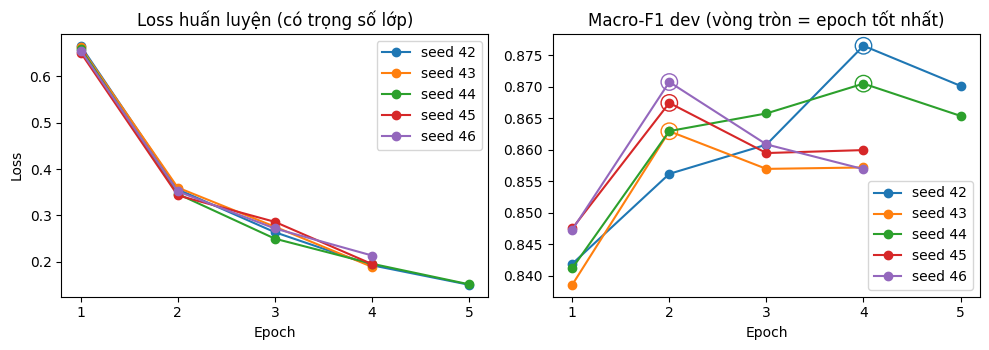

=== Kết quả trên DEV theo seed ===
 seed  best_epoch  n_epoch  macro_f1  accuracy  P_neutral  R_neutral  F1_neutral
   42           4        5    0.8765    0.9551     0.7797     0.6301      0.6970
   43           2        4    0.8629    0.9507     0.7143     0.6164      0.6618
   44           4        5    0.8705    0.9558     0.8235     0.5753      0.6774
   45           2        4    0.8674    0.9526     0.7015     0.6438      0.6714
   46           2        4    0.8708    0.9533     0.7231     0.6438      0.6812

=== Trung bình ± độ lệch chuẩn (5 seed) ===
macro_f1  : 0.8696 ± 0.0050
accuracy  : 0.9535 ± 0.0020
F1_neutral: 0.6777 ± 0.0130
Macro-F1 dev thấp nhất / cao nhất: 0.8629 / 0.8765
Tổng thời gian huấn luyện 5 seed: 15.8 phút

Macro-F1 dev trung bình của PhoBERT: 0.8696
So với SVM dev (0.7604): +0.1092 (cao hơn)
So với BiLSTM dev trung bình (0.8069): +0.0627 (cao hơn)


In [7]:
transformers.logging.set_verbosity_error()   # bớt in bảng LOAD REPORT lặp lại

SEEDS = [42, 43, 44, 45, 46]

# --- Huấn luyện các seed còn thiếu (seed 42 dùng lại từ ô 6) ---
for seed in SEEDS:
    if seed in RUNS:
        print(f'seed {seed}: đã có trong RUNS, bỏ qua\n')
        continue
    RUNS[seed] = train_model(seed)
    print()

# --- Tổng hợp từng seed (cùng định dạng ô 6) ---
rows = []
for seed in SEEDS:
    run = RUNS[seed]
    h = pd.DataFrame(run['hist'])
    print(f'===== Seed {seed} =====')
    print(f'Tổng thời gian huấn luyện: {h["sec"].sum() / 60:.1f} phút')
    print(f'Epoch tốt nhất: {run["best_epoch"]} | Macro-F1 dev tốt nhất: {run["best_dev_f1"]:.4f}')
    print(h.round(4).to_string(index=False))

    assert os.path.exists(run['ckpt']), f'Không thấy checkpoint của seed {seed}'
    model = load_best(run['ckpt'])
    res = evaluate(y_dv, predict(model, dev_loader), name=f'phobert_s{seed}', split='dev')
    del model
    gc.collect(); torch.cuda.empty_cache()
    print(f'Dev Macro-F1 sau khi nạp lại: {res["macro_f1"]:.4f} | Accuracy: {res["accuracy"]:.4f}\n')
    assert abs(res['macro_f1'] - run['best_dev_f1']) < 1e-3, f'Seed {seed}: nạp lại cho kết quả khác lúc huấn luyện'

    rows.append({'seed': seed, 'best_epoch': run['best_epoch'], 'n_epoch': len(run['hist']),
                 'macro_f1': res['macro_f1'], 'accuracy': res['accuracy'],
                 'P_neutral': res['P_neutral'], 'R_neutral': res['R_neutral'],
                 'F1_neutral': res['F1_neutral']})

# --- Learning curve của cả 5 seed ---
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for seed in SEEDS:
    h = pd.DataFrame(RUNS[seed]['hist'])
    ax[0].plot(h['epoch'], h['loss'], marker='o', label=f'seed {seed}')
    line, = ax[1].plot(h['epoch'], h['dev_macro_f1'], marker='o', label=f'seed {seed}')
    b = RUNS[seed]['best_epoch']
    ax[1].scatter([b], [h.loc[h['epoch'] == b, 'dev_macro_f1'].iloc[0]],
                  s=140, facecolors='none', edgecolors=line.get_color())
ax[0].set_title('Loss huấn luyện (có trọng số lớp)'); ax[0].set_ylabel('Loss')
ax[1].set_title('Macro-F1 dev (vòng tròn = epoch tốt nhất)')
for a in ax:
    a.set_xlabel('Epoch'); a.set_xticks(range(1, MAX_EPOCHS + 1)); a.legend()
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/fig_phobert_curve_all_seeds.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Bảng tổng hợp ---
dev_tab = pd.DataFrame(rows)
print('=== Kết quả trên DEV theo seed ===')
print(dev_tab.round(4).to_string(index=False))

print('\n=== Trung bình ± độ lệch chuẩn (5 seed) ===')
for col in ['macro_f1', 'accuracy', 'F1_neutral']:
    print(f'{col:10s}: {dev_tab[col].mean():.4f} ± {dev_tab[col].std():.4f}')
print(f'Macro-F1 dev thấp nhất / cao nhất: {dev_tab["macro_f1"].min():.4f} / {dev_tab["macro_f1"].max():.4f}')
print(f'Tổng thời gian huấn luyện 5 seed: {sum(sum(x["sec"] for x in RUNS[s]["hist"]) for s in SEEDS) / 60:.1f} phút')

# --- So với SVM và BiLSTM (cùng định dạng ô 6, dùng trung bình 5 seed) ---
mean_f1 = dev_tab['macro_f1'].mean()
print(f'\nMacro-F1 dev trung bình của PhoBERT: {mean_f1:.4f}')
for name, base in [('SVM dev', 0.7604), ('BiLSTM dev trung bình', 0.8069)]:
    diff = mean_f1 - base
    tag = 'cao hơn' if diff > 0 else 'THẤP HƠN'
    print(f"So với {name} ({base:.4f}): {diff:+.4f} ({tag})")

## 8. Chấm test một lần

Đây là lần **duy nhất** tập test được dùng cho PhoBERT. Ô này **không huấn luyện lại**: chỉ nạp 5 checkpoint đã lưu ở ô 7 (epoch tốt nhất theo dev của từng seed) rồi dự đoán 3166 câu test. Không có lựa chọn nào được thay đổi dựa trên kết quả test.

Đầu ra:
- Bảng test theo seed, trung bình ± độ lệch chuẩn (độ lệch chuẩn mẫu, giống notebook 05).
- Precision / Recall / F1 từng lớp (trung bình 5 seed).
- Ma trận nhầm lẫn **trung bình 5 seed** (không chọn một seed theo test), lưu `fig_cm_phobert_test.png`.
- Số câu neutral bị đoán sai, so với SVM (91) và BiLSTM (85,6).
- Lưu `phobert_test_metrics.csv`.
- So sánh với SVM (0,7399) và BiLSTM (0,7637 ± 0,0068) theo quy tắc đặt trước: chênh Macro-F1 **dưới 0,02 thì coi là tương đương**.

Số batch test: 50 | số câu: 3166


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]


=== Kết quả trên TEST theo seed ===
 seed  best_epoch  macro_f1  accuracy  F1_negative  F1_neutral  F1_positive  P_neutral  R_neutral  neutral_sai
   42           4    0.8388    0.9387       0.9566      0.6053       0.9546     0.6715     0.5509           75
   43           2    0.8332    0.9356       0.9524      0.5941       0.9530     0.6618     0.5389           77
   44           4    0.8454    0.9413       0.9570      0.6221       0.9571     0.7045     0.5569           74
   45           2    0.8438    0.9387       0.9575      0.6203       0.9536     0.6577     0.5868           69
   46           2    0.8353    0.9378       0.9543      0.5955       0.9563     0.6479     0.5509           75

=== Trung bình ± độ lệch chuẩn (5 seed) ===
macro_f1    : 0.8393 ± 0.0053
accuracy    : 0.9384 ± 0.0020
F1_negative : 0.9556 ± 0.0021
F1_neutral  : 0.6074 ± 0.0133
F1_positive : 0.9549 ± 0.0017
Macro-F1 test thấp nhất / cao nhất: 0.8332 / 0.8454

=== Precision / Recall / F1 từng lớp (trung bình 

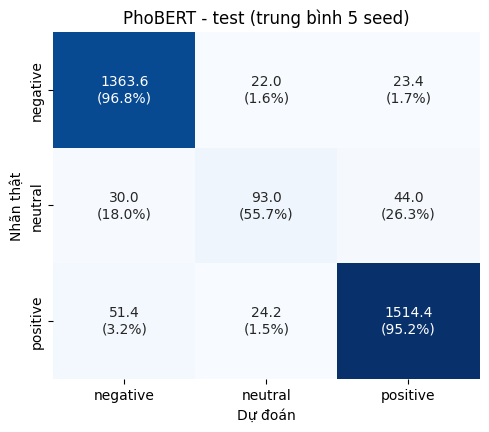

Đã lưu phobert_test_metrics.csv và fig_cm_phobert_test.png

Macro-F1 test trung bình của PhoBERT: 0.8393
So với SVM test (0.7399): +0.0994 (cao hơn)
So với BiLSTM test trung bình (0.7637): +0.0756 (cao hơn)
Seed thấp nhất của PhoBERT (0.8332) so với BiLSTM trung bình (0.7637): cao hơn


In [8]:
test_loader = make_loader(ids_te, y_te, shuffle=False)
print(f'Số batch test: {len(test_loader)} | số câu: {len(y_te)}')

rows, cms = [], []
for seed in SEEDS:
    run = RUNS[seed]
    assert os.path.exists(run['ckpt']), f'Thiếu checkpoint của seed {seed}'
    model = load_best(run['ckpt'])
    pred = predict(model, test_loader)
    del model
    gc.collect(); torch.cuda.empty_cache()

    assert len(pred) == len(y_te) == 3166
    cm = confusion_matrix(y_te, pred, labels=LABEL_IDS)
    assert cm.sum() == 3166 and cm.sum(axis=1).tolist() == [1409, 167, 1590], f'Ma trận seed {seed} sai tổng'
    cms.append(cm)

    res = evaluate(y_te, pred, name=f'phobert_s{seed}', split='test')
    res['seed'], res['best_epoch'] = seed, run['best_epoch']
    res['neutral_sai'] = int(cm[1].sum() - cm[1, 1])
    rows.append(res)

test_tab = pd.DataFrame(rows)
cols = ['seed', 'best_epoch', 'macro_f1', 'accuracy', 'F1_negative', 'F1_neutral', 'F1_positive',
        'P_neutral', 'R_neutral', 'neutral_sai']
print('\n=== Kết quả trên TEST theo seed ===')
print(test_tab[cols].round(4).to_string(index=False))

print('\n=== Trung bình ± độ lệch chuẩn (5 seed) ===')
for col in ['macro_f1', 'accuracy', 'F1_negative', 'F1_neutral', 'F1_positive']:
    print(f'{col:12s}: {test_tab[col].mean():.4f} ± {test_tab[col].std():.4f}')
print(f'Macro-F1 test thấp nhất / cao nhất: {test_tab["macro_f1"].min():.4f} / {test_tab["macro_f1"].max():.4f}')

print('\n=== Precision / Recall / F1 từng lớp (trung bình 5 seed) ===')
per_class = pd.DataFrame({lab: {m: test_tab[f'{m}_{lab}'].mean() for m in ['P', 'R', 'F1']} for lab in LABELS}).T
print(per_class.round(4).to_string())

mean_wrong = test_tab['neutral_sai'].mean()
print(f'\nSố câu neutral bị đoán sai (trung bình 5 seed): {mean_wrong:.1f}/167 '
      f'| SVM: 91/167 | BiLSTM: 85.6/167')

# --- Ma trận nhầm lẫn trung bình ---
cm_mean = np.mean(cms, axis=0)
cm_pct  = cm_mean / cm_mean.sum(axis=1, keepdims=True) * 100
annot = np.array([[f'{cm_mean[i, j]:.1f}\n({cm_pct[i, j]:.1f}%)' for j in range(3)] for i in range(3)])
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm_mean, annot=annot, fmt='', cmap='Blues', cbar=False, xticklabels=LABELS, yticklabels=LABELS)
plt.xlabel('Dự đoán'); plt.ylabel('Nhãn thật')
plt.title('PhoBERT - test (trung bình 5 seed)')
plt.savefig(f'{RESULTS_DIR}/fig_cm_phobert_test.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Lưu kết quả ---
test_tab.to_csv(f'{RESULTS_DIR}/phobert_test_metrics.csv', index=False, encoding='utf-8-sig')
print('Đã lưu phobert_test_metrics.csv và fig_cm_phobert_test.png')

# --- So sánh với SVM và BiLSTM (trung bình test, quy tắc ngưỡng 0.02) ---
mean_f1 = test_tab['macro_f1'].mean()
print(f'\nMacro-F1 test trung bình của PhoBERT: {mean_f1:.4f}')
for name, base in [('SVM test', 0.7399), ('BiLSTM test trung bình', 0.7637)]:
    diff = mean_f1 - base
    tag = 'tương đương' if abs(diff) < 0.02 else ('cao hơn' if diff > 0 else 'THẤP HƠN')
    print(f'So với {name} ({base:.4f}): {diff:+.4f} ({tag})')
print(f'Seed thấp nhất của PhoBERT ({test_tab["macro_f1"].min():.4f}) so với BiLSTM trung bình (0.7637): '
      f'{"cao hơn" if test_tab["macro_f1"].min() > 0.7637 else "không cao hơn"}')